# Редкие сегменты

Сегмент: группа клиентов с одним значением категориального признака (способ регистрации, город,
способ оплаты, длина тарифа). Сегмент считается редким, если в нём меньше 1000 клиентов.
Здесь выясняется, какие значения редкие и что с ними делать. Расчёты по полным данным, без выборки:
транзакции, участники и метки из `data/processed/`.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

P = "/workspace/data/processed/"
THRESH = 1000
BLUE, GRAY, INK = "#2a6fdb", "#b8bcc4", "#2b2f36"

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9cdd4",
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
    "axes.grid": True, "grid.color": "#e8eaee", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10,
})

con = duckdb.connect()
con.execute("SET memory_limit='4GB'; SET threads=2; SET enable_progress_bar=false")
con.execute(f'''
    CREATE VIEW members AS
    SELECT *
    FROM '{P}members.parquet'
''')
con.execute(f'''
    CREATE VIEW tr AS
    SELECT *
    FROM '{P}transactions.parquet'
''')
_ = con.execute(f'''
    CREATE VIEW labels AS
    SELECT *
    FROM '{P}labels.parquet'
''')

## Размеры сегментов
Для участников считаются клиенты по значению признака. Для способа оплаты и тарифа считаются клиенты,
у которых была хотя бы одна оплата с этим значением, и выручка (`actual_amount_paid` без отмен,
в тайваньских долларах).

In [2]:
seg = con.sql('''
    SELECT
        'registered_via' AS dim,
        registered_via::VARCHAR AS val,
        count(*) AS clients,
        NULL::DOUBLE AS revenue
    FROM members
    GROUP BY 2
    UNION ALL
    SELECT
        'city',
        city::VARCHAR,
        count(*),
        NULL
    FROM members
    GROUP BY 2
    UNION ALL
    SELECT
        'payment_method_id',
        payment_method_id::VARCHAR,
        count(DISTINCT msno),
        sum(actual_amount_paid)
    FROM tr
    WHERE is_cancel = 0
    GROUP BY 2
    UNION ALL
    SELECT
        'payment_plan_days',
        payment_plan_days::VARCHAR,
        count(DISTINCT msno),
        sum(actual_amount_paid)
    FROM tr
    WHERE is_cancel = 0
    GROUP BY 2
''').df()
seg["rare"] = seg.clients < THRESH


def summary(g: pd.DataFrame) -> pd.Series:
    """Сводка по одному признаку: сколько значений редких и какую долю они занимают.

    Args:
        g (pd.DataFrame): сегменты одного признака со столбцами `clients`, `revenue`, `rare`.

    Returns:
        pd.Series: число значений, число редких, доля клиентов в редких (только для признаков
            участников), доля выручки в редких (только для оплат), в процентах.
    """
    members_dim = g.revenue.isna().all()
    return pd.Series({
        "значений": len(g),
        "редких": int(g.rare.sum()),
        "доля клиентов в редких, %": np.nan if not members_dim else round(100 * g.clients[g.rare].sum() / g.clients.sum(), 2),
        "доля выручки в редких, %": np.nan if members_dim else round(100 * g.revenue[g.rare].sum() / g.revenue.sum(), 3),
    })


seg.groupby("dim").apply(summary, include_groups=False)

,значений,редких,"доля клиентов в редких, %","доля выручки в редких, %"
dim,,,,
city,21.0,0.0,0.00,NaN
payment_method_id,40.0,11.0,NaN,0.166
payment_plan_days,37.0,13.0,NaN,0.029
registered_via,18.0,7.0,0.04,NaN


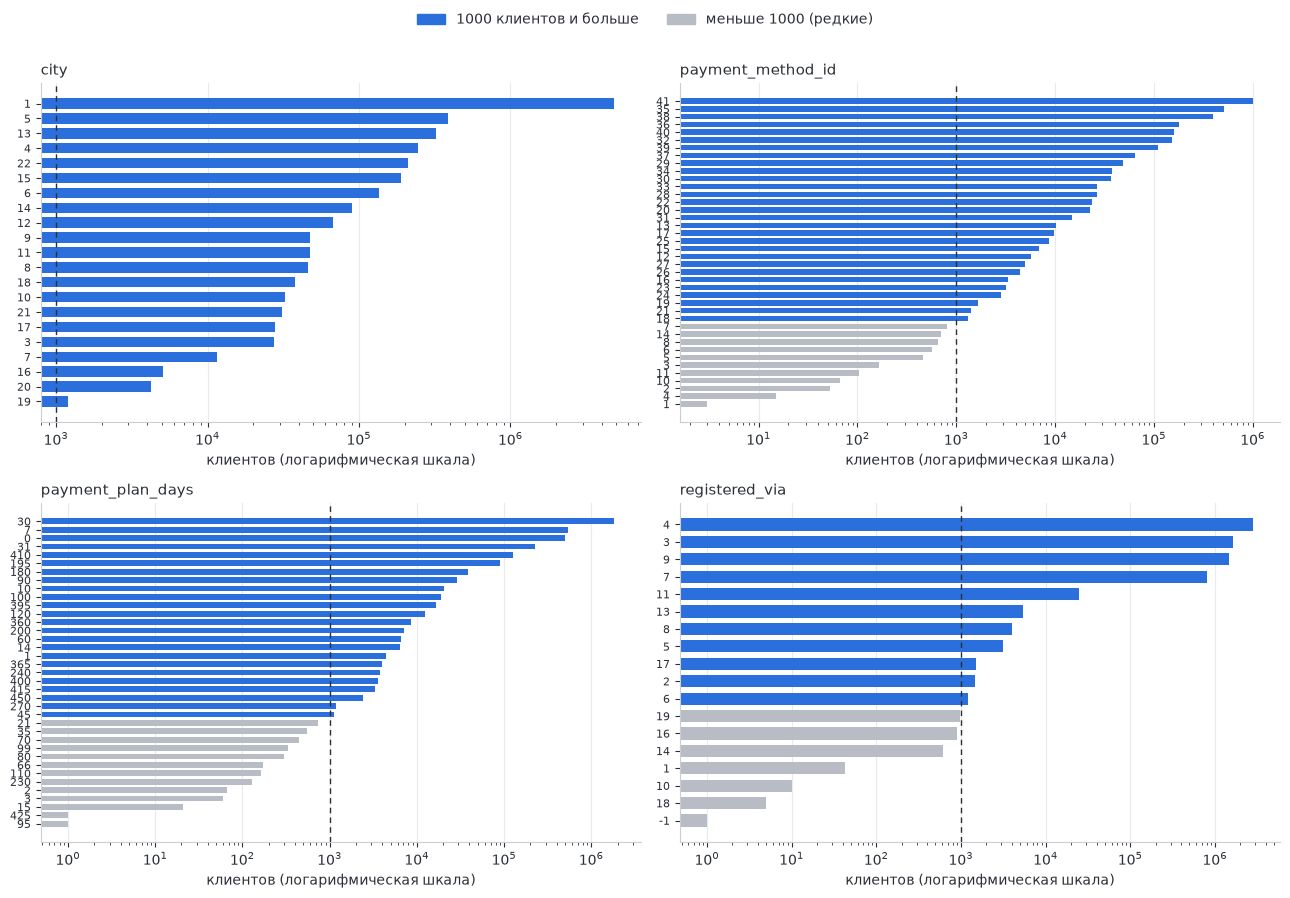

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (dim, g) in zip(axes.ravel(), seg.groupby("dim")):
    g = g.sort_values("clients")
    ax.barh(g.val, g.clients, color=np.where(g.rare, GRAY, BLUE), height=0.7)
    ax.set_xscale("log")
    ax.axvline(THRESH, color=INK, lw=1, ls=(0, (4, 3)))
    ax.set_title(dim, loc="left", fontsize=11)
    ax.set_xlabel("клиентов (логарифмическая шкала)")
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="y", visible=False)
fig.legend(handles=[Patch(color=BLUE, label=f"{THRESH} клиентов и больше"),
                    Patch(color=GRAY, label=f"меньше {THRESH} (редкие)")],
           loc="upper center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

## Насколько уверенно считается отток в редких сегментах
Метки февраля 2017 (`train`). Способ регистрации и город берутся из профиля, способ оплаты и тариф из
последней оплаты до 1 февраля. Доверительный интервал доли оттока (Вильсон, 95%) показывает, можно ли
сравнивать сегменты. Обозначения: `n` число клиентов с метками, «отток, %» доля оттока, «± п.п.» полуширина
интервала в процентных пунктах.

In [4]:
lab = con.sql('''
    WITH feb AS (
        SELECT
            msno,
            is_churn
        FROM labels
        WHERE expire_month = DATE '2017-02-01'
    ),
    last AS (
        SELECT
            msno,
            payment_method_id,
            payment_plan_days
        FROM tr
        JOIN feb USING (msno)
        WHERE transaction_date < DATE '2017-02-01'
            AND is_cancel = 0
        QUALIFY row_number() OVER (
            PARTITION BY msno
            ORDER BY transaction_date DESC, membership_expire_date DESC
        ) = 1
    )
    SELECT
        feb.msno,
        feb.is_churn,
        members.registered_via,
        members.city,
        last.payment_method_id,
        last.payment_plan_days
    FROM feb
    LEFT JOIN members USING (msno)
    LEFT JOIN last USING (msno)
''').df()


def wilson_half(p: pd.Series, n: pd.Series, z: float = 1.96) -> pd.Series:
    """Считает полуширину доверительного интервала Вильсона для доли.

    Args:
        p (pd.Series): доля (от 0 до 1).
        n (pd.Series): число наблюдений.
        z (float): квантиль нормального распределения (1,96 для 95%).

    Returns:
        pd.Series: полуширина интервала в долях.
    """
    return z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)


rows = []
for dim in ["registered_via", "city", "payment_method_id", "payment_plan_days"]:
    g = lab.groupby(dim).is_churn.agg(["size", "mean"]).reset_index()
    g.columns = ["val", "n", "churn"]
    g["dim"] = dim
    g["val"] = g.val.astype("Int64").astype(str)
    g["ci_pp"] = 100 * wilson_half(g.churn, g.n)
    rows.append(g)
seg_churn = pd.concat(rows).merge(seg[["dim", "val", "rare"]], on=["dim", "val"], how="left")
seg_churn["rare"] = seg_churn.rare.fillna(True)
seg_churn.groupby(["dim", "rare"]).agg(
    сегментов=("val", "size"), клиентов_с_метками=("n", "sum"),
    медиана_n=("n", "median"), медиана_ширины_ДИ_пп=("ci_pp", "median"),
).round(1)

сегментов  клиентов_с_метками  медиана_n  \
dim               rare                                              
city              False         21              877161     9036.0   
payment_method_id False         27              990124     1991.0   
                  True           6                 708       32.0   
payment_plan_days False         24              990772      251.5   
                  True           8                  60        7.0   
registered_via    False          5              877161   105445.0   

                         медиана_ширины_ДИ_пп  
dim               rare                         
city              False                   0.6  
payment_method_id False                   0.7  
                  True                   11.1  
payment_plan_days False                   5.3  
                  True                   26.7  
registered_via    False                   0.2

In [5]:
rare_tbl = seg_churn[seg_churn.rare].sort_values(["dim", "n"], ascending=[True, False]).copy()
rare_tbl["churn_pct"] = (100 * rare_tbl.churn).round(1)
rare_tbl["ci_pp"] = rare_tbl.ci_pp.round(1)
print(rare_tbl[["dim", "val", "n", "churn_pct", "ci_pp"]]
      .rename(columns={"churn_pct": "отток, %", "ci_pp": "± п.п."})
      .to_string(index=False))

              dim val   n  отток, %  ± п.п.
payment_method_id  14 545       0.2     0.5
payment_method_id  11  75       0.0     2.4
payment_method_id  10  36       0.0     4.8
payment_method_id   8  28      53.6    17.3
payment_method_id   3  12      50.0    24.6
payment_method_id   6  12      75.0    22.2
payment_plan_days 110  18      38.9    20.5
payment_plan_days  70  14      50.0    23.2
payment_plan_days  35   9      88.9    20.8
payment_plan_days  21   8      87.5    22.4
payment_plan_days  80   6      66.7    30.2
payment_plan_days 230   3      66.7    36.5
payment_plan_days   3   1     100.0    39.7
payment_plan_days  66   1       0.0    39.7


## Выводы
- Редких значений (меньше 1000 клиентов) немало: 7 из 18 способов регистрации, 11 из 40 способов оплаты, 13 из 37 длин тарифа. Городов с малым числом клиентов нет.
- Вместе они почти ничего не весят: менее 0,05% участников по способу регистрации, 0,17% выручки по способам оплаты и 0,03% по тарифам.
- Отток в них оценивается неуверенно. Для редких способов оплаты в метках февраля всего 708 клиентов, медианная ширина доверительного интервала 11 п. п. (для остальных 0,7 п. п.). Для редких тарифов 60 клиентов с метками и интервал 27 п. п. (для остальных 5 п. п.).
- Решение: в аналитике и модели значения с числом клиентов меньше 1000 объединяются в категорию «other», отдельные выводы по ним не делаются.
- Ограничение: порог 1000 условный. Даже для нередких тарифов медиана числа клиентов с метками 250, интервал около 5 п. п., поэтому и по ним выводы делаются осторожно.